In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Загрузка данных
df = pd.read_excel('Courses_KG.xlsx')  

In [ ]:
def count_gender(dataframe, column):
    gender_counts = {}
    for gender in dataframe[column]:
        if gender in gender_counts:
            gender_counts[gender] += 1
        else:
            gender_counts[gender] = 1
    return gender_counts

# Подсчет общего количества учащихся по полу
gender_count = count_gender(df, 'Gender')
print("Количество учащихся по полу:\n", gender_count)


Количество учащихся по полу:
 {'M': 115, 'F': 86}


In [ ]:
def count_certificates(dataframe, column):
    certificate_counts = {}
    for status in dataframe[column]:
        if status in certificate_counts:
            certificate_counts[status] += 1
        else:
            certificate_counts[status] = 1
    return certificate_counts

# Подсчет общего количества участников, получивших сертификат
certificate_count = count_certificates(df, 'Certificate')
print("\nКоличество участников, получивших сертификат:\n", certificate_count)



Количество участников, получивших сертификат:
 {'Certificated': 154, 'Not certificated': 47}


In [ ]:
def count_classes(dataframe, column):
    class_counts = {}
    for course in dataframe[column]:
        if course in class_counts:
            class_counts[course] += 1
        else:
            class_counts[course] = 1
    return dict(sorted(class_counts.items()))

# Подсчет общего количества участников по каждому виду класса
class_count = count_classes(df, 'Course')
print("\nКоличество участников по каждому виду класса:\n", class_count)



Количество участников по каждому виду класса:
 {'Class 1': 16, 'Class 10': 17, 'Class 11': 9, 'Class 12': 12, 'Class 13': 31, 'Class 14': 6, 'Class 2': 17, 'Class 3': 17, 'Class 4': 13, 'Class 5': 12, 'Class 6': 6, 'Class 7': 16, 'Class 8  ': 11, 'Class 9': 18}


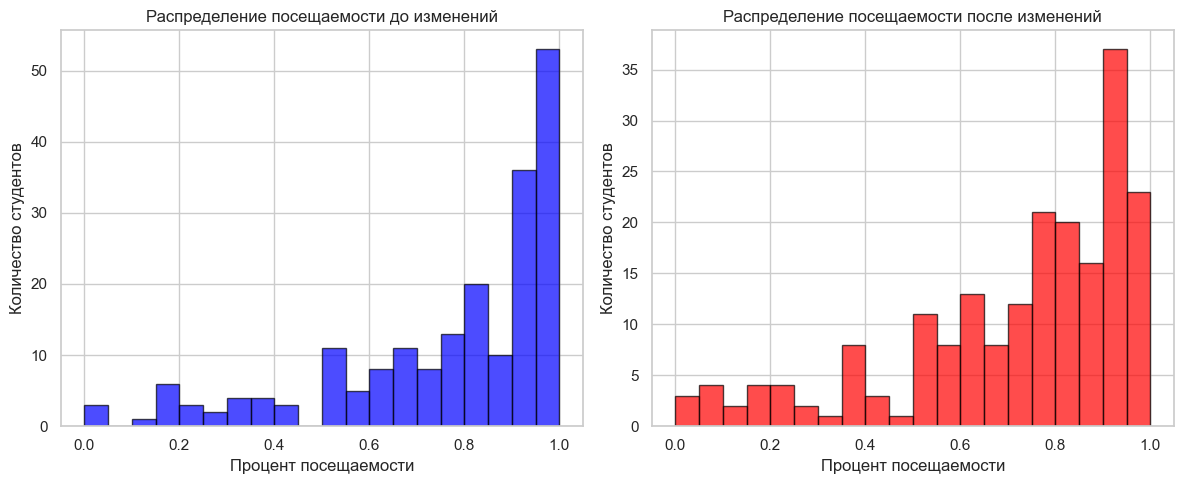

In [ ]:
df_copy = df.copy() 

df_copy['Late Flag'] = np.random.randint(0, 2, size=len(df))
df_copy['Late Status'] = df_copy['Late Flag'].map({0: 'Не опаздывал', 1: 'Опаздывал'})

df_copy.loc[df_copy['Late Flag'] == 1, 'Attendance Rate'] -= np.random.uniform(
    0.05, 0.15, size=df_copy['Late Flag'].sum()
)
df_copy['Attendance Rate'] = df_copy['Attendance Rate'].clip(0, 1)

# Определение статуса студентов
def determine_status(attendance_rate):
    return 'Отличник' if 0.8 <= attendance_rate <= 1 else 'Не выполнил требования курса'

df_copy['Status'] = df_copy['Attendance Rate'].apply(determine_status)

# Сохранение изменений в файл
df_copy.to_excel('updated_Courses_KG.xlsx', index=False)

updated_df = pd.read_excel('updated_Courses_KG.xlsx')

# Построение графиков
plt.figure(figsize=(12, 5))

# График до изменений
plt.subplot(1, 2, 1)
plt.hist(df['Attendance Rate'], bins=20, color='blue', alpha=0.7, edgecolor='black')
plt.title('Распределение посещаемости до изменений')
plt.xlabel('Процент посещаемости')
plt.ylabel('Количество студентов')

# График после изменений
plt.subplot(1, 2, 2)
plt.hist(updated_df['Attendance Rate'], bins=20, color='red', alpha=0.7, edgecolor='black')
plt.title('Распределение посещаемости после изменений')
plt.xlabel('Процент посещаемости')
plt.ylabel('Количество студентов')

# Отображение графиков
plt.tight_layout()
plt.show()


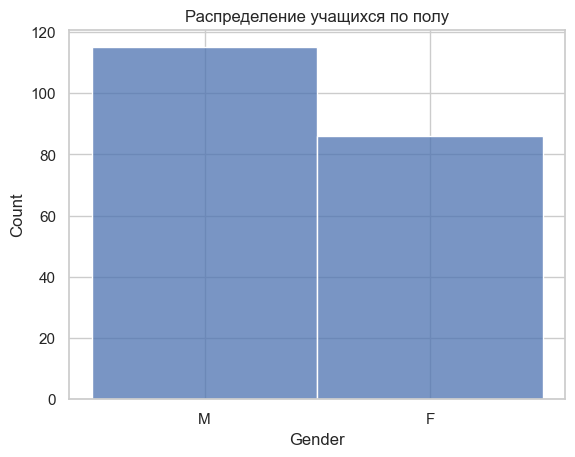

In [ ]:
# Гистограмма распределения по полу
sns.histplot(data=df, x='Gender', discrete=True)
plt.title('Распределение учащихся по полу')
plt.show()

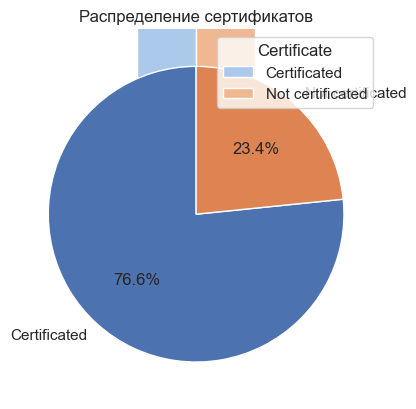

In [ ]:
# Круговая диаграмма статуса сертификата
certificate_counts = df['Certificate'].value_counts()
sns.set(style="whitegrid")
sns.barplot(hue=certificate_counts.index, y=certificate_counts.values, palette='pastel')
plt.pie(certificate_counts, labels=certificate_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Распределение сертификатов')
plt.show()

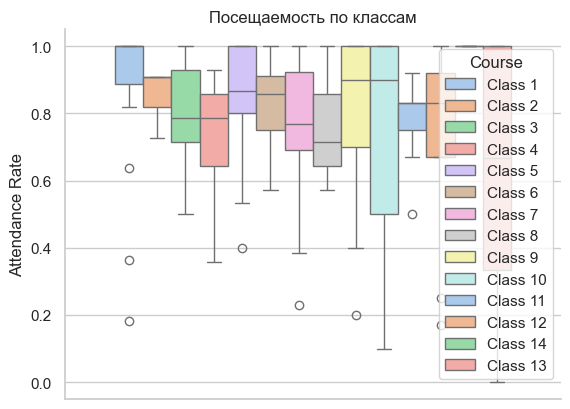

In [ ]:
# Создание боксплота посещаемости по классам
sns.boxplot(hue='Course', y='Attendance Rate', data=df, palette='pastel')
sns.despine()  # Убирает верхнюю и правую границы для более чистого вида
plt.title('Посещаемость по классам')
plt.show()

### Тепловая карта корреляции
numeric_columns = df.select_dtypes(include=['number']).columns
if len(numeric_columns) > 1:
    corr = df[numeric_columns].corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm')
    plt.title('Тепловая карта корреляции')
    plt.show()
else:
    print("Недостаточно числовых данных для построения тепловой карты корреляции.")

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [ ]:
# Преобразуем целевую переменную в бинарный формат
df["Certificate"] = df["Certificate"].apply(lambda x: 1 if x == "Certificated" else 0)


In [ ]:
# 1 способ: Выбираем независимые переменные
features_1 = ["Age", "Attendance Rate"]
X1 = df[features_1].copy()
y = df["Certificate"]
X1 = X1.fillna(X1.mean())

In [ ]:
# Разделение данных (70/30)
X1_train, X1_test, y_train, y_test = train_test_split(X1, y, test_size=0.3, random_state=42)

In [ ]:
# Создание и обучение модели
model1 = LogisticRegression()
model1.fit(X1_train, y_train)

In [ ]:
# Предсказание и оценка
y_pred1 = model1.predict(X1_test)
accuracy1 = accuracy_score(y_test, y_pred1)
conf_matrix1 = confusion_matrix(y_test, y_pred1)
class_report1 = classification_report(y_test, y_pred1)

# Вывод результатов
print("1 способ: Точность модели:", accuracy1)
print("Матрица ошибок:\n", conf_matrix1)
print("Отчет классификации:\n", class_report1)


1 способ: Точность модели: 0.8688524590163934
Матрица ошибок:
 [[ 7  8]
 [ 0 46]]
Отчет классификации:
               precision    recall  f1-score   support

           0       1.00      0.47      0.64        15
           1       0.85      1.00      0.92        46

    accuracy                           0.87        61
   macro avg       0.93      0.73      0.78        61
weighted avg       0.89      0.87      0.85        61



In [ ]:
def predict_certificate(age, attendance_rate, gender, position):
    # Подготовка числовых данных
    input_data = pd.DataFrame([[age, attendance_rate]], columns=["Age", "Attendance Rate"])
    
    # Кодирование пола
    gender_df = pd.DataFrame([[gender]], columns=["Gender"])
    gender_encoded = pd.get_dummies(gender_df, drop_first=True)

    # Кодирование позиции
    position_df = pd.DataFrame([[position]], columns=["Position"])
    position_encoded = pd.get_dummies(position_df)

    # Объединяем всё в один датафрейм
    input_data = pd.concat([input_data, gender_encoded, position_encoded], axis=1)

    # Заполняем пропуски, если есть
    input_data = input_data.fillna(0)

    # Подгоняем порядок и наличие колонок под те, которые были при обучении
    all_expected_columns = ["Age", "Attendance Rate", "Gender_M", "Position_A", "Position_B", "Position_C"]  # замените на свои реальные значения
    input_data = input_data.reindex(columns=all_expected_columns, fill_value=0)

    # Предсказание
    prediction = model1.predict(input_data)

    # Результат
    if prediction[0] == 1:
        print("Результат: Студент получит сертификат.")
    else:
        print("Результат: Студент не получит сертификат.")


age = float(input("Введите возраст студента: "))
attendance_rate = float(input("Введите процент посещаемости студента: "))
gender = input("Введите пол студента (male/female): ")
position = input("Введите позицию студента (например, A/B/C): ")

predict_certificate(age, attendance_rate, gender, position)



Введите возраст студента:  20
Введите процент посещаемости студента:  0.3
Введите пол студента (male/female):  male
Введите позицию студента (например, A/B/C):  spec


ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- Gender_M
- Position_A
- Position_B
- Position_C


In [ ]:
# 2 способ: Используем другие независимые переменные
features_2 = ["Age", "Attendance Rate", "Gender"]  # Добавляем пол
X2 = df[features_2].copy()
X2 = pd.get_dummies(X2, drop_first=True)  # Кодируем категориальные переменные
X2 = X2.fillna(X2.mean())

In [ ]:
# Разделение данных (80/20)
X2_train, X2_test, y_train, y_test = train_test_split(X2, y, test_size=0.2, random_state=42)

In [ ]:
# Создание и обучение модели
model2 = LogisticRegression()
model2.fit(X2_train, y_train)

In [ ]:
# Предсказание и оценка
y_pred2 = model2.predict(X2_test)
accuracy2 = accuracy_score(y_test, y_pred2)
conf_matrix2 = confusion_matrix(y_test, y_pred2)
class_report2 = classification_report(y_test, y_pred2)


In [ ]:
# Вывод результатов
print("2 способ: Точность модели:", accuracy2)
print("Матрица ошибок:\n", conf_matrix2)
print("Отчет классификации:\n", class_report2)

# Заключение:
print("Вывод: Логистическая регрессия показывает разные результаты в зависимости от набора признаков.")


2 способ: Точность модели: 0.8536585365853658
Матрица ошибок:
 [[ 5  6]
 [ 0 30]]
Отчет классификации:
               precision    recall  f1-score   support

           0       1.00      0.45      0.62        11
           1       0.83      1.00      0.91        30

    accuracy                           0.85        41
   macro avg       0.92      0.73      0.77        41
weighted avg       0.88      0.85      0.83        41

Вывод: Логистическая регрессия показывает разные результаты в зависимости от набора признаков.


In [ ]:
features_3 = ["Age", "Attendance Rate", "Gender", "Position"]
X3 = df[features_3].copy()
X3 = pd.get_dummies(X3, drop_first=True)  # кодируем Gender и Position
X3 = X3.fillna(X3.mean())
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X3_train, X3_test, y_train, y_test = train_test_split(X3, y, test_size=0.2, random_state=42)

model3 = LogisticRegression()
model3.fit(X3_train, y_train)
def predict_certificate(age, attendance_rate, gender, position):
    input_data = pd.DataFrame([[age, attendance_rate, gender, position]], columns=["Age", "Attendance Rate", "Gender", "Position"])
    
    input_data = pd.get_dummies(input_data, drop_first=True)
    
    # Обеспечиваем совпадение структуры с обучением
    input_data = input_data.reindex(columns=model3.feature_names_in_, fill_value=0)
    
    prediction = model3.predict(input_data)
    
    if prediction[0] == 1:
        print("Результат: Студент получит сертификат.")
    else:
        print("Результат: Студент не получит сертификат.")
age = float(input("Введите возраст студента: "))
attendance_rate = float(input("Введите процент посещаемости: "))
gender = input("Введите пол студента (male/female): ")
position = input("Введите позицию (например, A, B, C): ")

predict_certificate(age, attendance_rate, gender, position)


Введите возраст студента:  21
Введите процент посещаемости:  0.3
Введите пол студента (male/female):  male
Введите позицию (например, A, B, C):  a


Результат: Студент не получит сертификат.


### Заключение

# Контрольные вопросы:


### 1. Матрица ошибок

### 2. Метрики для оценки качества модели

### 3. Использованные библиотеки


### 4. Логистическая регрессия


### 5. Обучение без учителя


### 6. Обучение с учителем
